# Predict computation time for large dataset

## Define Dataset

In [ ]:
from rdkit import Chem
import numpy as np
import pandas as pd
from DataAnalysis.functions import computationTime_analysis
from sklearn.linear_model import LinearRegression
import warnings

warnings.filterwarnings("ignore") #there is a compability warning but you can ignore it

counter = 0
smiles_list = []

with open("../data/enamine.smiles", "r") as f:
    for line in f:
        try:
            parts = line.strip().split()
            if len(parts) == 0:
                continue
            smiles = parts[0]
            name = parts[1] if len(parts) > 1 else "Unknown"

            mol = Chem.MolFromSmiles(smiles)
            if mol is None:
                print(f"Invalid SMILES: {smiles}")
                continue

            smiles_list.append(smiles)

        except AttributeError as e:
            print(f"AttributeError for line: {line.strip()} — {e}")
            continue

print(f'Number of entries: {len(smiles_list)}')


## Extract Number of Spins

In [2]:
def count_hydrogens(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None  # Invalid SMILES
    total_H = 0
    for atom in mol.GetAtoms():
        total_H += atom.GetTotalNumHs()
    return total_H

# Build DataFrame from SMILES and H count
data = []

for molecule in smiles_list:
    h_count = count_hydrogens(molecule)
    data.append({
        "SMILES": molecule,
        "Hydrogen_Count": h_count
    })

h_df = pd.DataFrame(data)
h_df.head()

,SMILES,Hydrogen_Count
0,CC(OC=1C=CC=C(C#N)C1)C(=O)N2CCCCC2C(=O)O,18
1,CCC(=O)NC1=CC=C(F)C(=C1)S(=O)(=O)NC(C)(C)C,19
2,O=C(CN1C=CC=N1)NC2=NC=3C=CC=CC3N2C4CCCC4,19
3,O=C1OCCN1C=2C=CC(=CC2)S(=O)(=O)NC=3C=CC=CC3F,13
4,O=S(=O)(CC1CCCCO1)NC=2C=CC=CC2C3=NN=C4CCCCCN34,26


# Choose previously calculated spectra

In [3]:
df = pd.read_csv("../spectra_simulator/YYYY0625_HHmmss_combined_HPC.csv")
grouped_means = df.groupby('n_spins')['computation_time'].mean().reset_index()
grouped_means.tail()

,n_spins,computation_time
8,9,46.864600
9,10,465.836704
10,11,479.162935
11,12,2225.611662
12,13,20835.470347


## Define your Model

For example the exponential model; It predicts the minimal computation time, because the number of j-couplings would have a significant impact, but we don't know them in this stage.

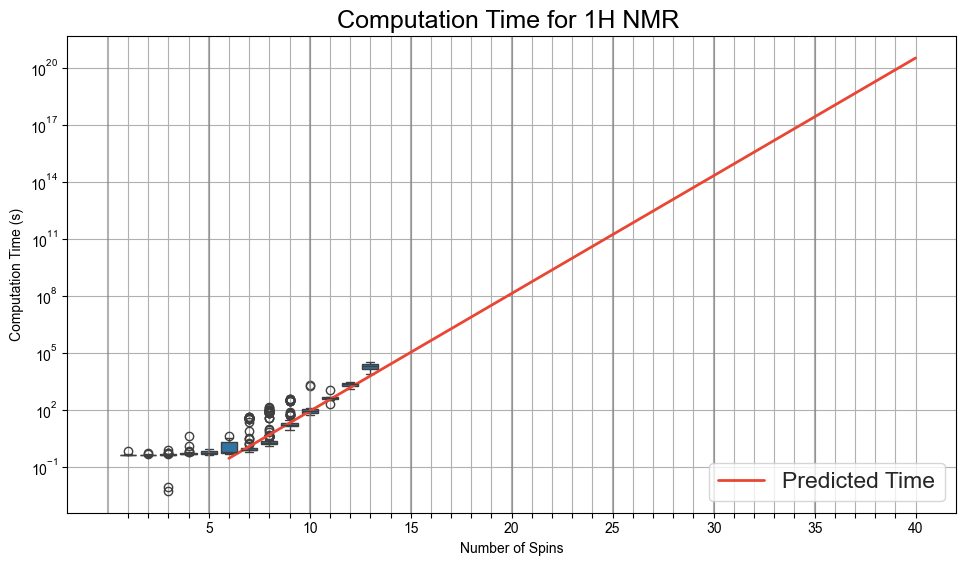

In [4]:
filtered_df = df[(df['n_spins'] >= 7) ].copy() # ignore molecule with less than 7 spins
filtered_df = filtered_df[filtered_df['computation_time'] > 0] # ignore failed molecules

# Take the log of computation time
X = filtered_df[['n_spins']]
y_log = np.log(filtered_df['computation_time'])

# Fit linear model to log-transformed target
model = LinearRegression()
model.fit(X, y_log)
n_spins_range = np.arange(6, 41).reshape(-1, 1)
predicted_log_times = model.predict(pd.DataFrame(n_spins_range, columns=['n_spins']))

# Convert back to original scale
predicted_times = np.exp(predicted_log_times)
predicted_times = np.clip(predicted_times, 0, None)
m1_predictions_df = pd.DataFrame({
    'n_spins': n_spins_range.flatten(),
    'predicted_computation_time': predicted_times
})

computationTime_analysis.boxplot(df,
                                 yscale='log',
                                 filename_plot='computation_time_with_exponential_fit.png',
                                 save=True,
                                 regression_df=m1_predictions_df)

In [5]:
# Step 1: Count Hydrogen_Count occurrences
h_counts = h_df['Hydrogen_Count'].value_counts().sort_index()

# Step 2: Predict computation_time for each Hydrogen_Count
def predict_times_from_series(n_spins_series, model):
    predicted_log_times = model.predict(pd.DataFrame(n_spins_series, columns=['n_spins']))
    return np.exp(predicted_log_times)

# Get the unique Hydrogen_Count values
hydrogen_values = np.array(h_counts.index)

# Predict computation_time for each
predicted_times = predict_times_from_series(hydrogen_values, model)

# Step 3: Multiply predicted times by counts
total_times = predicted_times * h_counts.values

# Step 4: Create result DataFrame
estimated_df = pd.DataFrame({
    'Hydrogen_Count': hydrogen_values,
    'Count': h_counts.values,
    'Predicted_Computation_Time': predicted_times,
    'Total_Estimated_Time': total_times
})

# Optional: get total overall computation time
total_overall_time = estimated_df['Total_Estimated_Time'].sum()

# View detailed breakdown
print(estimated_df)


Estimated total computation time: 44315780575168844267520.00
    Hydrogen_Count  Count  Predicted_Computation_Time  Total_Estimated_Time
0                3      1                4.055475e-03          4.055475e-03
1                4      3                1.688570e-02          5.065711e-02
2                5     28                7.030669e-02          1.968587e+00
3                6     69                2.927346e-01          2.019869e+01
4                7    287                1.218854e+00          3.498110e+02
5                8    817                5.074918e+00          4.146208e+03
6                9   1870                2.113034e+01          3.951373e+04
7               10   3382                8.797999e+01          2.975483e+05
8               11   5632                3.663206e+02          2.063118e+06
9               12   8612                1.525242e+03          1.313539e+07
10              13  12561                6.350622e+03          7.977017e+07
11              14  16929  

In [6]:
time = estimated_df["Total_Estimated_Time"].sum()
total_hours = time / 3600
total_years = total_hours / (365 * 24)

print(f"Total predicted computation time: {total_years} years")

Total predicted computation time: 1405244183636759.5 years
